In [1]:
df = spark.table("crop_yield_features")
df.printSchema()

2025-06-24 06:42:11,309 WARN conf.HiveConf: HiveConf of name hive.stats.jdbc.timeout does not exist
2025-06-24 06:42:11,311 WARN conf.HiveConf: HiveConf of name hive.stats.retries.wait does not exist


root
 |-- region: string (nullable = true)
 |-- soil_type: string (nullable = true)
 |-- crop: string (nullable = true)
 |-- rainfall: double (nullable = true)
 |-- temperature: double (nullable = true)
 |-- fertilizer: integer (nullable = true)
 |-- irrigation: integer (nullable = true)
 |-- weather_condition: string (nullable = true)
 |-- days_to_harvest: integer (nullable = true)
 |-- yield: double (nullable = true)



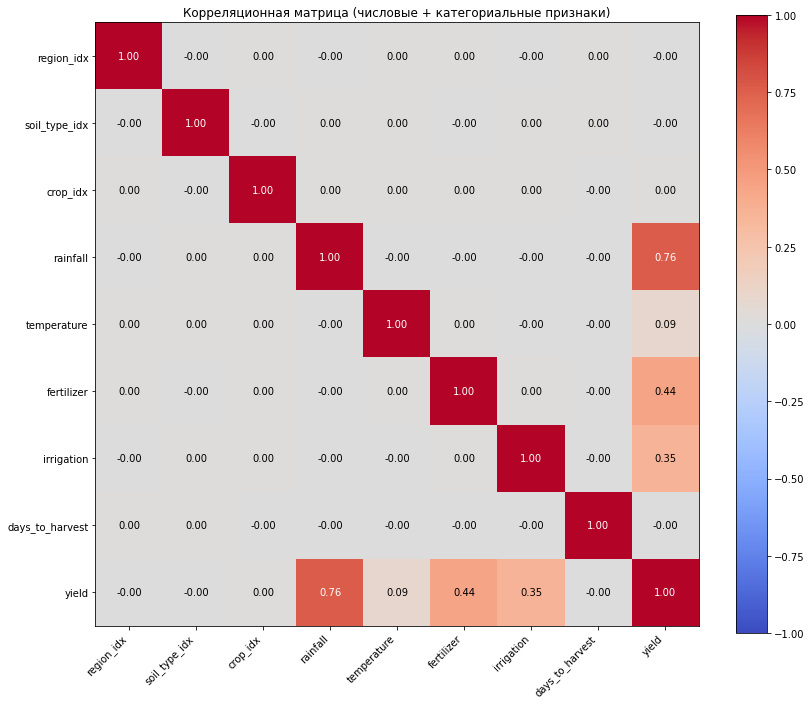

In [6]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.stat import Correlation
import matplotlib.pyplot as plt
import numpy as np
 
# 1. Инициализация SparkSession
spark = SparkSession.builder \
    .appName("CorrelationMatrixWithLabels") \
    .enableHiveSupport() \
    .getOrCreate()
 
# 2. Загрузка данных из витрины
df = spark.sql("SELECT * FROM crop_yield_features")
 
# 3. Категориальные признаки
categorical_cols = ["region", "soil_type", "crop"]
indexers = [StringIndexer(inputCol=col, outputCol=col + "_idx").fit(df) for col in categorical_cols]
for indexer in indexers:
    df = indexer.transform(df)
 
# 4. Формирование списка всех числовых признаков
numeric_cols = ["rainfall", "temperature", "fertilizer", "irrigation", "days_to_harvest", "yield"]
indexed_cols = [col + "_idx" for col in categorical_cols]
feature_cols = indexed_cols + numeric_cols
 
# 5. Сбор признаков в вектор
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df = assembler.transform(df)
 
# 6. Корреляция (Pearson)
matrix = Correlation.corr(df, "features").head()[0].toArray()
 
# 7. Построение матрицы с matplotlib и подписями значений
plt.figure(figsize=(12, 10))
plt.imshow(matrix, cmap="coolwarm", interpolation="none", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(feature_cols)), feature_cols, rotation=45, ha="right")
plt.yticks(range(len(feature_cols)), feature_cols)
 
# 8. Добавление значений
for i in range(len(matrix)):
    for j in range(len(matrix)):
        plt.text(j, i, f"{matrix[i][j]:.2f}", ha='center', va='center',
                 color='white' if abs(matrix[i][j]) > 0.6 else 'black')
 
plt.title("Корреляционная матрица (числовые + категориальные признаки)")
plt.tight_layout()
plt.show()

In [95]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline

# 1. Инициализация SparkSession
spark = SparkSession.builder \
    .appName("LinearRegressionWithScaledFeatures") \
    .enableHiveSupport() \
    .getOrCreate()

# 2. Загрузка данных
df = spark.table("crop_yield_features")

# 3. Категориальные признаки (исключаем crop)
categorical_cols = ["region", "soil_type"]
indexers = [StringIndexer(inputCol=col, outputCol=col + "_idx", handleInvalid='keep')
            for col in categorical_cols]

# 4. Числовые признаки
numeric_cols = ["rainfall", "temperature", "fertilizer", "irrigation", "days_to_harvest"]

# 5. Сбор всех признаков (сырые перед масштабированием)
feature_cols = [col + "_idx" for col in categorical_cols] + numeric_cols
assembler = VectorAssembler(inputCols=feature_cols, outputCol="rawFeatures")

# 6. Стандартизация признаков
scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withMean=True, withStd=True)

# 7. Модель линейной регрессии
lr = LinearRegression(featuresCol="features", labelCol="yield")

# 8. Pipeline
pipeline = Pipeline(stages=indexers + [assembler, scaler, lr])

# 9. Разбиение на train/test
train, test = df.randomSplit([0.8, 0.2], seed=42)

# 10. Обучение модели
model = pipeline.fit(train)

# 11. Предсказания
test_pred = model.transform(test)

# 12. Оценка качества
evaluator_rmse = RegressionEvaluator(labelCol="yield", predictionCol="prediction", metricName="rmse")
rmse = evaluator_rmse.evaluate(test_pred)

evaluator_r2 = RegressionEvaluator(labelCol="yield", predictionCol="prediction", metricName="r2")
r2 = evaluator_r2.evaluate(test_pred)

print(f"RMSE on test data: {rmse:.4f}")
print(f"R2 on test data:   {r2:.4f}")

# 13. Важность признаков (коэффициенты)
# Извлечение обученной модели линейной регрессии
lr_model = model.stages[-1]
coefficients = lr_model.coefficients.toArray().tolist()

# 14. Сбор и сортировка важности признаков
feat_importance = list(zip(feature_cols, coefficients))
feat_importance_sorted = sorted(feat_importance, key=lambda x: abs(x[1]), reverse=True)

print("Feature Importances (coefficients after scaling):")
for feat, coef in feat_importance_sorted:
    print(f"{feat}: {coef:.4f}")


2025-06-24 18:49:33,365 WARN util.Instrumentation: [30d973e1] regParam is zero, which might cause numerical instability and overfitting.


RMSE on test data: 0.5008
R2 on test data:   0.9129
Feature Importances (coefficients after scaling):
rainfall: 1.2973
fertilizer: 0.7498
irrigation: 0.5994
temperature: 0.1436
soil_type_idx: 0.0007
days_to_harvest: 0.0002
region_idx: 0.0000


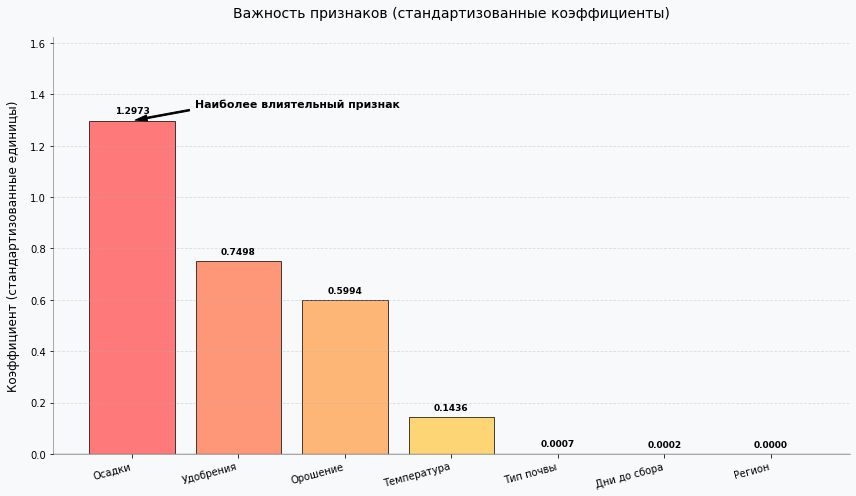

In [123]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Данные из результатов модели (русские названия признаков)
features = ['Осадки', 'Удобрения', 'Орошение', 'Температура', 'Тип почвы', 'Дни до сбора', 'Регион']
importances = [1.2973, 0.7498, 0.5994, 0.1436, 0.0007, 0.0002, 0.0000]

# Создаем градиентную цветовую карту
colors = LinearSegmentedColormap.from_list('importance', ['#FF6B6B', '#FFD166', '#06D6A0'])(np.linspace(0, 1, len(features)))

# Создание диаграммы
plt.figure(figsize=(12, 7), facecolor='#f8f9fa')  # светлый фон
ax = plt.gca()
ax.set_facecolor('#f8f9fa')  # цвет фона области графика

# Создание столбцов с градиентной заливкой и контурами
bars = plt.bar(features, importances, color=colors, 
               edgecolor='black', linewidth=0.8, alpha=0.9)

# Настройка подписей
plt.ylabel('Коэффициент (стандартизованные единицы)', fontsize=12, labelpad=10)
plt.title('Важность признаков (стандартизованные коэффициенты)', fontsize=14, pad=20)
plt.xticks(rotation=15, ha='right', fontsize=10)
plt.ylim(0, max(importances) * 1.25)

# Добавление значений над столбцами
for i, v in enumerate(importances):
    plt.text(i, v + 0.02, f"{v:.4f}", 
             ha='center', va='bottom', 
             fontsize=9, fontweight='bold')

# Горизонтальная сетка
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Аннотация для важных признаков
plt.annotate('Наиболее влиятельный признак', 
             xy=(0, importances[0]), 
             xytext=(1.55, 1.35),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=6),
             ha='center', fontsize=11, fontweight='bold')

# Удаление верхней и правой границ
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_alpha(0.4)
ax.spines['bottom'].set_alpha(0.4)

# Добавим горизонтальную линию нуля
plt.axhline(y=0, color='gray', linestyle='-', alpha=0.3)

plt.tight_layout()
plt.show()

In [97]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import StringIndexer, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline

# 1. Инициализация SparkSession
spark = SparkSession.builder \
    .appName("CompareModelsCropYield") \
    .enableHiveSupport() \
    .getOrCreate()

# 2. Загрузка данных
df = spark.table("crop_yield_features")

# 3. Индексация категориальных признаков (кроме crop)
categorical_cols = ["region", "soil_type"]
indexers = [StringIndexer(inputCol=col, outputCol=col + "_idx", handleInvalid='keep')
            for col in categorical_cols]

# 4. Числовые признаки
numeric_cols = ["rainfall", "temperature", "fertilizer", "irrigation", "days_to_harvest"]

# 5. Сбор вектора сырых признаков
feature_cols = [col + "_idx" for col in categorical_cols] + numeric_cols
assembler = VectorAssembler(inputCols=feature_cols, outputCol="rawFeatures")

# 6. Стандартизация для Linear Regression
scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withMean=True, withStd=True)

# 7. Определение моделей
lr = LinearRegression(featuresCol="features", labelCol="yield")
rf = RandomForestRegressor(featuresCol="rawFeatures", labelCol="yield", numTrees=50, maxDepth=5)
gbt = GBTRegressor(featuresCol="rawFeatures", labelCol="yield", maxIter=50, maxDepth=5)

# 8. Пайплайны для каждой модели
pipeline_lr = Pipeline(stages=indexers + [assembler, scaler, lr])
pipeline_rf = Pipeline(stages=indexers + [assembler, rf])
pipeline_gbt = Pipeline(stages=indexers + [assembler, gbt])

# 9. Разбиение на train/test
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

# 10. Обучение моделей
model_lr = pipeline_lr.fit(train_df)
model_rf = pipeline_rf.fit(train_df)
model_gbt = pipeline_gbt.fit(train_df)

# 11. Предсказания
pred_lr = model_lr.transform(test_df).select("prediction", "yield")
pred_rf = model_rf.transform(test_df).select("prediction", "yield")
pred_gbt = model_gbt.transform(test_df).select("prediction", "yield")

# 12. Оценка качества
evaluator = RegressionEvaluator(labelCol="yield", predictionCol="prediction")
metrics = {}
for name, pred in [("Linear Regression", pred_lr),
                   ("Random Forest", pred_rf),
                   ("GBT", pred_gbt)]:
    rmse = evaluator.evaluate(pred, {evaluator.metricName: "rmse"})
    r2 = evaluator.evaluate(pred, {evaluator.metricName: "r2"})
    metrics[name] = (rmse, r2)
    print(f"{name}: RMSE = {rmse:.4f}, R2 = {r2:.4f}")

# 13. Вывод метрик в упорядоченном виде
print("\nСводка метрик:")
for name in ["Linear Regression", "Random Forest", "GBT"]:
    rmse, r2 = metrics[name]
    print(f"- {name:<18} RMSE: {rmse:.4f}, R2: {r2:.4f}")


2025-06-24 19:10:10,266 WARN util.Instrumentation: [e1f9223b] regParam is zero, which might cause numerical instability and overfitting.
2025-06-24 19:11:08,364 WARN memory.MemoryStore: Not enough space to cache rdd_1067_0 in memory! (computed 212.1 MiB so far)
2025-06-24 19:11:08,365 WARN storage.BlockManager: Persisting block rdd_1067_0 to disk instead.


Linear Regression: RMSE = 0.5008, R2 = 0.9129


Random Forest: RMSE = 0.6385, R2 = 0.8584


GBT: RMSE = 0.5037, R2 = 0.9119

Сводка метрик:
- Linear Regression  RMSE: 0.5008, R2: 0.9129
- Random Forest      RMSE: 0.6385, R2: 0.8584
- GBT                RMSE: 0.5037, R2: 0.9119


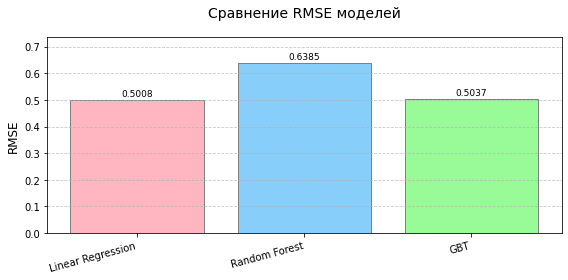

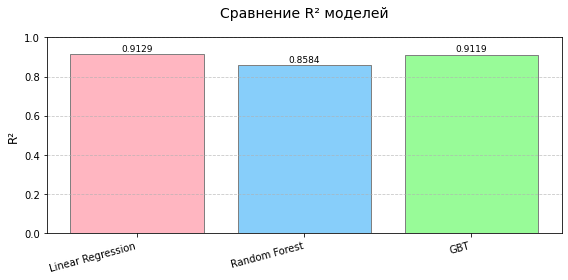

In [108]:
import matplotlib.pyplot as plt

# Модели и метрики
models = ['Linear Regression', 'Random Forest', 'GBT']
rmse_values = [0.5008, 0.6385, 0.5037]
r2_values = [0.9129, 0.8584, 0.9119]

# Светлые цвета для каждого столбца
colors = ['#FFB6C1', '#87CEFA', '#98FB98']  # Розовый, голубой, зеленый

# График RMSE
plt.figure(figsize=(8, 4))
bars = plt.bar(models, rmse_values, color=colors, edgecolor='gray')
plt.ylabel('RMSE', fontsize=12)
plt.title('Сравнение RMSE моделей', fontsize=14, pad=20)

# Добавление значений на столбцы
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., 
             height + 0.005, 
             f'{height:.4f}', 
             ha='center', 
             va='bottom',
             fontsize=9)

plt.xticks(rotation=15, ha='right')
plt.ylim(0, max(rmse_values)*1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# График R²
plt.figure(figsize=(8, 4))
bars = plt.bar(models, r2_values, color=colors, edgecolor='gray')
plt.ylabel('R²', fontsize=12)
plt.title('Сравнение R² моделей', fontsize=14, pad=20)

# Добавление значений на столбцы
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., 
             height + 0.005, 
             f'{height:.4f}', 
             ha='center', 
             va='bottom',
             fontsize=9)

plt.xticks(rotation=15, ha='right')
plt.ylim(0, 1.0)  # R² всегда в диапазоне [0,1]
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [133]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml import Pipeline
from pyspark.sql.functions import expr, avg, first

# 1. Инициализация SparkSession
spark = SparkSession.builder \
    .appName("RainfallDrynessClustersAnalysis") \
    .enableHiveSupport() \
    .getOrCreate()

# 2. Загрузка данных из витрины
df = spark.table("crop_yield_features")

# 3. Кластеризация по количеству осадков (rainfall)
assembler = VectorAssembler(inputCols=["rainfall"], outputCol="rawFeatures")
scaler = StandardScaler(inputCol="rawFeatures", outputCol="features", withMean=True, withStd=True)
kmeans = KMeans(featuresCol="features", predictionCol="dryness_cluster", k=3, seed=42)
pipeline = Pipeline(stages=[assembler, scaler, kmeans])
model = pipeline.fit(df)
clustered = model.transform(df)

# 4. Оценка качества кластеризации (Silhouette Score)
evaluator = ClusteringEvaluator(featuresCol="features", predictionCol="dryness_cluster",
                                metricName="silhouette", distanceMeasure="squaredEuclidean")
silhouette = evaluator.evaluate(clustered)
print(f"Silhouette Score (3 clusters by rainfall): {silhouette:.4f}")

# 5. Анализ кластеров: распределение по кластерам и средний урожай в каждом
clustered.groupBy("dryness_cluster").count().orderBy("dryness_cluster").show()
clustered.groupBy("dryness_cluster").agg(
    avg("rainfall").alias("avg_rainfall"),
    avg("yield").alias("avg_yield")
).orderBy("dryness_cluster").show()

# 6. Сравнение урожая с и без орошения внутри каждого кластера
summary_irrigation = clustered.groupBy("dryness_cluster", "irrigation").agg(
    avg("yield").alias("avg_yield")
).orderBy("dryness_cluster", "irrigation")
summary_irrigation.show()

# 7. Сохранение результатов в новые таблицы
# Кластеры
df_clusters = clustered.select("region", "soil_type", "crop", "rainfall", "irrigation", "yield", "dryness_cluster")
df_clusters.write.mode("overwrite").saveAsTable("rainfall_dryness_clusters")
# Сводка по урожаю и орошению
pivot_irrig = summary_irrigation \
    .groupBy("dryness_cluster") \
    .pivot("irrigation", [0, 1]) \
    .agg(first("avg_yield").alias("avg_yield")) \
    .orderBy("dryness_cluster") 
pivot_irrig.write.mode("overwrite").saveAsTable("irrigation_vs_yield_by_cluster")


Silhouette Score (3 clusters by rainfall): 0.7523


+---------------+------+
|dryness_cluster| count|
+---------------+------+
|              0|333097|
|              1|333350|
|              2|333322|
+---------------+------+



+---------------+------------------+------------------+
|dryness_cluster|      avg_rainfall|         avg_yield|
+---------------+------------------+------------------+
|              0|249.94279312304718|3.1523199164649354|
|              1|  550.160241950497| 4.652048553523141|
|              2| 849.9278280098343| 6.146395939691915|
+---------------+------------------+------------------+



+---------------+----------+-----------------+
|dryness_cluster|irrigation|        avg_yield|
+---------------+----------+-----------------+
|              0|         0|2.553013818896231|
|              0|         1|3.753316037481751|
|              1|         0|4.051375604896358|
|              1|         1|5.250828859546257|
|              2|         0|5.548607390389844|
|              2|         1|6.747219477989285|
+---------------+----------+-----------------+



/tmp/ipykernel_5681/2603672272.py:6: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-whitegrid')


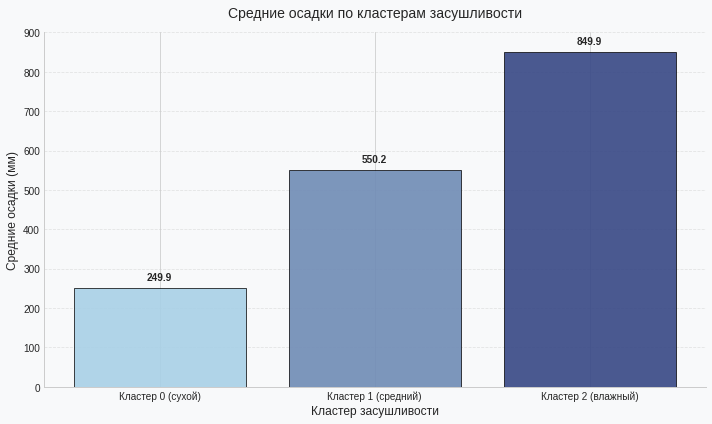

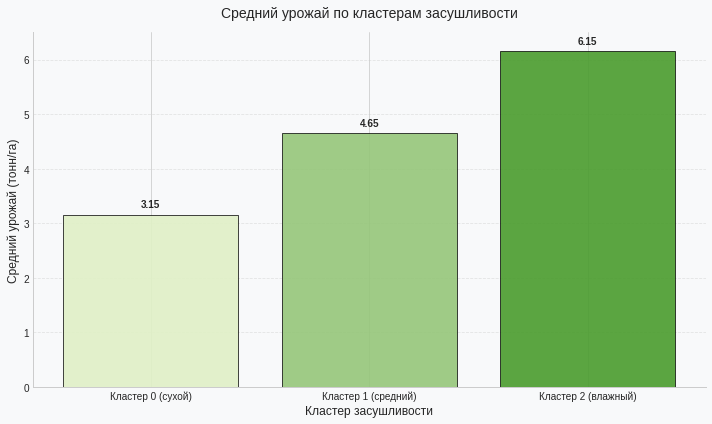

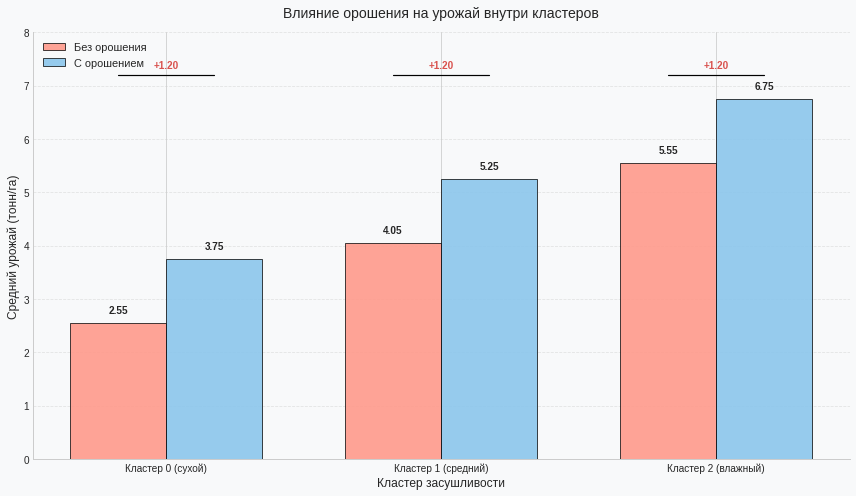

In [140]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Настройка стиля
plt.style.use('seaborn-whitegrid')

# 1. График средних осадков по кластерам
plt.figure(figsize=(10, 6), facecolor='#f8f9fa')
ax = plt.gca()
ax.set_facecolor('#f8f9fa')

# Градиент синего для осадков
rain_colors = LinearSegmentedColormap.from_list('rain', ['#a8d0e6', '#374785'])(np.linspace(0, 1, 3))

bars = plt.bar(clusters, avg_rainfall, color=rain_colors, edgecolor='black', linewidth=0.8, alpha=0.9)
plt.xlabel('Кластер засушливости', fontsize=12)
plt.ylabel('Средние осадки (мм)', fontsize=12)
plt.title('Средние осадки по кластерам засушливости', fontsize=14, pad=15)
plt.ylim(0, 900)

for i, v in enumerate(avg_rainfall):
    plt.text(i, v + 15, f"{v:.1f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# 2. График среднего урожая по кластерам
plt.figure(figsize=(10, 6), facecolor='#f8f9fa')
ax = plt.gca()
ax.set_facecolor('#f8f9fa')

# Градиент зеленого для урожая
yield_colors = LinearSegmentedColormap.from_list('yield', ['#e0f0c6', '#4a9c2d'])(np.linspace(0, 1, 3))

bars = plt.bar(clusters, avg_yield, color=yield_colors, edgecolor='black', linewidth=0.8, alpha=0.9)
plt.xlabel('Кластер засушливости', fontsize=12)
plt.ylabel('Средний урожай (тонн/га)', fontsize=12)
plt.title('Средний урожай по кластерам засушливости', fontsize=14, pad=15)
plt.ylim(0, 6.5)

for i, v in enumerate(avg_yield):
    plt.text(i, v + 0.1, f"{v:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# 3. Группированный график влияния орошения (с исправленной линией разницы)
plt.figure(figsize=(12, 7), facecolor='#f8f9fa')
ax = plt.gca()
ax.set_facecolor('#f8f9fa')

x = np.arange(len(clusters))
width = 0.35

# Цвета для орошения
no_irr_color = '#ff9a8b'
with_irr_color = '#8bc6ec'

bars1 = plt.bar(x - width/2, [irrigation_data[c][0] for c in [0, 1, 2]], 
               width, color=no_irr_color, edgecolor='black', 
               linewidth=0.8, alpha=0.9, label='Без орошения')

bars2 = plt.bar(x + width/2, [irrigation_data[c][1] for c in [0, 1, 2]], 
               width, color=with_irr_color, edgecolor='black', 
               linewidth=0.8, alpha=0.9, label='С орошением')

plt.xlabel('Кластер засушливости', fontsize=12)
plt.ylabel('Средний урожай (тонн/га)', fontsize=12)
plt.title('Влияние орошения на урожай внутри кластеров', fontsize=14, pad=15)
plt.xticks(x, clusters)
plt.ylim(0, 8)
plt.legend(fontsize=11, loc='upper left')

# Добавление значений (поднято выше)
for i, cluster in enumerate([0, 1, 2]):
    plt.text(i - width/2, irrigation_data[cluster][0] + 0.15,  # Поднято выше
             f"{irrigation_data[cluster][0]:.2f}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')
    plt.text(i + width/2, irrigation_data[cluster][1] + 0.15,  # Поднято выше
             f"{irrigation_data[cluster][1]:.2f}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Линия разницы (поднята значительно выше)
for i, cluster in enumerate([0, 1, 2]):
    diff = irrigation_data[cluster][1] - irrigation_data[cluster][0]
    y_pos = max(irrigation_data[cluster][1] + 0.4, 7.2)  # Автоподбор высоты
    plt.plot([i - width/2, i + width/2], [y_pos, y_pos], 
             'k-', lw=1.2)
    plt.text(i, y_pos + 0.1, 
             f"+{diff:.2f}", 
             ha='center', va='bottom', fontsize=10, fontweight='bold', color='#d9534f')

plt.grid(axis='y', linestyle='--', alpha=0.5)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()